In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet("../data/processed/reviews_clean.parquet")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"],
)

print(train_df.shape, test_df.shape)
print(train_df["sentiment"].value_counts(normalize=True))
print(test_df["sentiment"].value_counts(normalize=True))

(40000, 3) (10000, 3)
sentiment
positive    0.506625
negative    0.493375
Name: proportion, dtype: float64
sentiment
positive    0.5066
negative    0.4934
Name: proportion, dtype: float64


In [2]:
train_df.to_parquet("../data/processed/train.parquet", index=False)
test_df.to_parquet("../data/processed/test.parquet", index=False)

In [3]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

train_df = pd.read_parquet("../data/processed/train.parquet")
test_df = pd.read_parquet("../data/processed/test.parquet")

# 1. Turn text into TF-IDF vectors (fit on TRAIN only!)
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),   # single words AND two-word phrases
    min_df=3,             # ignore words in fewer than 3 reviews
    max_features=100_000,
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])   # transform only, no fit

y_train = train_df["sentiment"]
y_test = test_df["sentiment"]

print("Matrix shape:", X_train.shape)

# 2. Train logistic regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 3. Evaluate on the test set
pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("F1 (macro):", f1_score(y_test, pred, average="macro"))
print(classification_report(y_test, pred))

Matrix shape: (40000, 100000)
Accuracy: 0.9017
F1 (macro): 0.9016732305370136
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      4934
    positive       0.90      0.91      0.90      5066

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



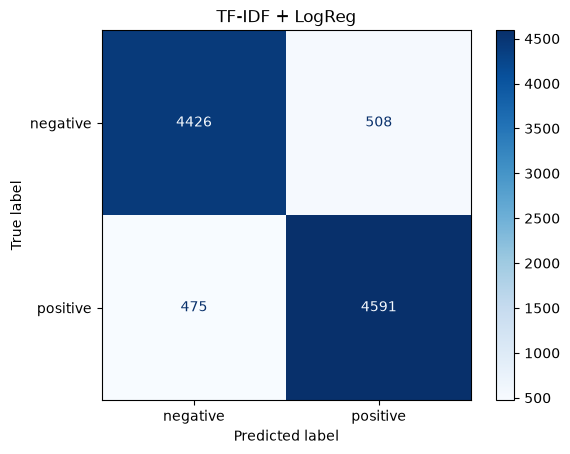

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("TF-IDF + LogReg")
plt.show()

In [6]:
import numpy as np

feature_names = np.array(vectorizer.get_feature_names_out())
coefs = model.coef_[0]          # one weight per feature
order = np.argsort(coefs)

print("Most NEGATIVE features:")
print(list(feature_names[order[:20]]))
print("\nMost POSITIVE features:")
print(list(feature_names[order[-20:]]))

Most NEGATIVE features:
['not', 'boring', 'poor', 'worst', 'disappointed', 'disappointing', 'waste', 'disappointment', 'terrible', 'bad', 'horrible', 'not worth', 'money', 'the worst', 'no', 'nothing', 'awful', 'don', 'instead', 'unfortunately']

Most POSITIVE features:
['favorite', 'classic', 'loved', 'well', 'enjoyed', 'works', 'and', 'nice', 'easy', 'fun', 'the best', 'awesome', 'wonderful', 'amazing', 'perfect', 'love', 'good', 'best', 'excellent', 'great']


In [7]:
errors = test_df[pred != y_test.values].copy()
errors["predicted"] = pred[pred != y_test.values]

for _, row in errors.sample(10, random_state=1).iterrows():
    print(f"TRUE: {row['sentiment']} | PRED: {row['predicted']}")
    print(row["text"][:300], "\n")

TRUE: negative | PRED: positive
Science of Today: This book was a disappointment. The author, like so many other Catholic authors addressing the interpretation of Genesis, makes the fundamental exegetical error of accepting uncritically the Darwinian hypothesis of an old earth. While Father's arguments in favor of a literal interp 

TRUE: positive | PRED: negative
It may ruin his career but that's all Kit has left to lose: Kit knows there is something connecting the sudden demise of these doctors but his boss at the FBI has told him in no uncertain terms that Kit must drop it or lose his job. Frannie still is unable to move past her husband's death. Every nig 

TRUE: negative | PRED: positive
DIVE!!: I am a huge Hip fan. I have every CD of there's. This is by far there worst CD ever. The Hip have a really good habit of making each CD sound different. The single My Music@Work is the only track worth listening too. Maybe listening to them for years, and seeing them live on multiple occas

In [8]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(vectorizer, "../models/tfidf_vectorizer.joblib")
joblib.dump(model, "../models/logreg_sentiment.joblib")

# save predictions for later model comparison
test_df = test_df.copy()
test_df["pred_tfidf"] = pred
test_df.to_parquet("../data/processed/test_preds.parquet", index=False)